# 4. Colonia de hormigas

La optimización por colonia de hormigas (*ant colony optimization*, ACO) construye soluciones paso a paso con una población de agentes, las hormigas, que eligen cada componente de la solución al azar. La probabilidad de elegir un componente combina dos fuentes de información. La primera es la feromona (*pheromone*), una memoria que la colonia acumula sobre los componentes que aparecieron en buenas soluciones; la segunda es la información heurística (*heuristic information*), que mide qué tan atractivo parece el componente por sí solo, por ejemplo el inverso de una distancia. Después de cada iteración, la feromona se evapora en parte y las hormigas depositan feromona nueva en los componentes que usaron, en proporción a la calidad de su solución. Así, los componentes de las buenas soluciones ganan probabilidad en las iteraciones siguientes.

El capítulo trae cinco ejemplos. El primero es el problema del agente viajero, donde se presentan la regla de transición, la evaporación y el depósito tal como los implementa el código. Los siguientes adaptan esas mismas reglas a otros problemas: la mochila (con un ajuste de parámetros mediante Optuna), la asignación de recursos a tareas cuando los beneficios cambian con el tiempo, la selección de variables para un clasificador y una política de inventario con demanda estocástica.

In [1]:
import random
import time

import numpy as np
import matplotlib.pyplot as plt

## El problema del agente viajero

En el problema del agente viajero (*traveling salesman problem*, TSP) se tiene un conjunto de $n$ ciudades con distancias $d_{ij}$ entre cada par, y se busca el recorrido que visita cada ciudad una vez y regresa al punto de partida con la menor longitud total.

### Representación y construcción de una solución

Una solución es una permutación de las ciudades, guardada como una lista con el orden de visita; el regreso de la última ciudad a la primera se suma al calcular la longitud. Cada hormiga parte de una ciudad elegida al azar y, mientras queden ciudades sin visitar, escoge la siguiente con la regla de transición. La colonia guarda la feromona en una matriz $\tau$ de tamaño $n \times n$, que empieza con $\tau_{ij} = 0{,}1$ fuera de la diagonal y cero en ella.

### Regla de transición

La información heurística es la visibilidad, el inverso de la distancia:

$$\eta_{ij} = \frac{1}{d_{ij}}.$$

Si la hormiga está en la ciudad $i$ y $N_i$ es el conjunto de ciudades que aún no ha visitado, la probabilidad de pasar a la ciudad $j \in N_i$ es

$$p_{ij} = \frac{\tau_{ij}^{\alpha}\,\eta_{ij}^{\beta}}{\sum_{l \in N_i} \tau_{il}^{\alpha}\,\eta_{il}^{\beta}}.$$

El exponente $\alpha$ pondera la feromona y $\beta$ la visibilidad. Con $\alpha = 0$ la hormiga se comporta como una heurística golosa aleatorizada que solo mira la distancia; con $\beta = 0$ solo sigue la memoria de la colonia.

### Evaporación y depósito

Cuando todas las hormigas terminan sus recorridos, la feromona se actualiza en dos pasos. Primero se evapora una fracción $\rho$ de toda la matriz:

$$\tau_{ij} \leftarrow (1-\rho)\,\tau_{ij}.$$

Luego cada hormiga $k$, cuyo recorrido $T_k$ tiene longitud $L_k$, deposita feromona en cada arco de su recorrido, incluido el arco de regreso a la ciudad inicial:

$$\tau_{ij} \leftarrow \tau_{ij} + \frac{Q}{L_k}, \qquad (i,j) \in T_k.$$

Como el problema es simétrico, el código deposita la misma cantidad en $\tau_{ij}$ y en $\tau_{ji}$. Los recorridos cortos depositan más feromona por arco, y la evaporación hace que los arcos que dejan de usarse pierdan peso con el tiempo.

### Código

La clase `ColoniaHormigasTSP` reúne la matriz de feromonas y los parámetros. El método `seleccionar_siguiente_ciudad` aplica la regla de transición, `construir_solucion` arma el recorrido de una hormiga, `actualizar_feromonas` hace la evaporación y el depósito, y `optimizar` repite el ciclo durante `max_iter` iteraciones y guarda la mejor longitud encontrada hasta cada iteración.

In [2]:
class ColoniaHormigasTSP:
    """
    Implementación del algoritmo de Colonia de Hormigas para resolver el Problema del Viajante (TSP)

    Atributos:
        n_ciudades (int): Número de ciudades
        distancias (np.array): Matriz de distancias entre ciudades
        n_hormigas (int): Número de hormigas en la colonia
        alpha (float): Importancia de las feromonas (α)
        beta (float): Importancia de la información heurística (β)
        rho (float): Tasa de evaporación de feromonas (ρ)
        Q (float): Constante de depósito de feromonas
        feromonas (np.array): Matriz de feromonas entre ciudades
    """

    def __init__(self, distancias, n_hormigas=20, alpha=1.0, beta=2.0, rho=0.1, Q=100):
        self.n_ciudades = len(distancias)
        self.distancias = distancias
        self.n_hormigas = n_hormigas
        self.alpha = alpha
        self.beta = beta
        self.rho = rho
        self.Q = Q

        # Inicializar matriz de feromonas con valores pequeños uniformes
        self.feromonas = np.ones((self.n_ciudades, self.n_ciudades)) * 0.1
        np.fill_diagonal(self.feromonas, 0)  # No hay feromonas en la diagonal

    def calcular_visibilidad(self):
        """
        Calcula la matriz de visibilidad (información heurística).
        La visibilidad es el inverso de la distancia.
        """
        with np.errstate(divide='ignore'):
            visibilidad = 1 / self.distancias
        np.fill_diagonal(visibilidad, 0)
        return visibilidad

    def seleccionar_siguiente_ciudad(self, hormiga_pos, ciudades_no_visitadas, visibilidad):
        """
        Selecciona la siguiente ciudad usando la regla de probabilidad.

        Args:
            hormiga_pos (int): Ciudad actual de la hormiga
            ciudades_no_visitadas (list): Lista de ciudades no visitadas
            visibilidad (np.array): Matriz de visibilidad

        Returns:
            int: Siguiente ciudad seleccionada
        """
        if len(ciudades_no_visitadas) == 0:
            return None

        # Calcular probabilidades de selección
        feromonas_temp = self.feromonas[hormiga_pos, ciudades_no_visitadas]
        visibilidad_temp = visibilidad[hormiga_pos, ciudades_no_visitadas]

        probabilidades = (feromonas_temp ** self.alpha) * (visibilidad_temp ** self.beta)
        probabilidades = probabilidades / np.sum(probabilidades)

        # Seleccionar siguiente ciudad
        siguiente_ciudad = np.random.choice(ciudades_no_visitadas, p=probabilidades)
        return siguiente_ciudad

    def construir_solucion(self, visibilidad):
        """
        Construye una solución (ruta) para una hormiga.

        Args:
            visibilidad (np.array): Matriz de visibilidad

        Returns:
            tuple: (ruta, longitud_total)
        """
        ciudad_inicial = np.random.randint(self.n_ciudades)
        ruta = [ciudad_inicial]
        ciudades_no_visitadas = list(range(self.n_ciudades))
        ciudades_no_visitadas.remove(ciudad_inicial)

        while ciudades_no_visitadas:
            siguiente = self.seleccionar_siguiente_ciudad(ruta[-1], ciudades_no_visitadas, visibilidad)
            ruta.append(siguiente)
            ciudades_no_visitadas.remove(siguiente)

        # Calcular longitud total de la ruta
        longitud_total = sum(self.distancias[ruta[i], ruta[i+1]] for i in range(len(ruta)-1))
        longitud_total += self.distancias[ruta[-1], ruta[0]]  # Volver al inicio

        return ruta, longitud_total

    def actualizar_feromonas(self, todas_rutas, todas_longitudes):
        """
        Actualiza la matriz de feromonas según las rutas construidas.

        Args:
            todas_rutas (list): Lista de rutas construidas por las hormigas
            todas_longitudes (list): Lista de longitudes de las rutas
        """
        # Evaporación de feromonas
        self.feromonas *= (1 - self.rho)

        # Depósito de nuevas feromonas
        for ruta, longitud in zip(todas_rutas, todas_longitudes):
            for i in range(len(ruta) - 1):
                self.feromonas[ruta[i], ruta[i+1]] += self.Q / longitud
                self.feromonas[ruta[i+1], ruta[i]] += self.Q / longitud
            # Conectar última ciudad con la primera
            self.feromonas[ruta[-1], ruta[0]] += self.Q / longitud
            self.feromonas[ruta[0], ruta[-1]] += self.Q / longitud

    def optimizar(self, max_iter=100):
        """
        Ejecuta el algoritmo de optimización.

        Args:
            max_iter (int): Número máximo de iteraciones

        Returns:
            tuple: (mejor_ruta, mejor_longitud, historial_longitudes)
        """
        visibilidad = self.calcular_visibilidad()
        mejor_ruta = None
        mejor_longitud = float('inf')
        historial_longitudes = []

        for iteracion in range(max_iter):
            # Construir soluciones para todas las hormigas
            todas_rutas = []
            todas_longitudes = []

            for _ in range(self.n_hormigas):
                ruta, longitud = self.construir_solucion(visibilidad)
                todas_rutas.append(ruta)
                todas_longitudes.append(longitud)

                # Actualizar mejor solución
                if longitud < mejor_longitud:
                    mejor_longitud = longitud
                    mejor_ruta = ruta.copy()

            # Actualizar feromonas
            self.actualizar_feromonas(todas_rutas, todas_longitudes)
            historial_longitudes.append(mejor_longitud)

        return mejor_ruta, mejor_longitud, historial_longitudes

Las dos funciones siguientes generan una instancia con ciudades ubicadas al azar en un cuadrado de lado 100, con distancias euclidianas, y dibujan un recorrido.

In [3]:
def generar_ciudades_aleatorias(n_ciudades):
    """
    Genera coordenadas aleatorias para las ciudades y calcula la matriz de distancias.

    Args:
        n_ciudades (int): Número de ciudades a generar

    Returns:
        tuple: (coordenadas, matriz_distancias)
    """
    coordenadas = np.random.rand(n_ciudades, 2) * 100
    distancias = np.zeros((n_ciudades, n_ciudades))

    for i in range(n_ciudades):
        for j in range(n_ciudades):
            distancias[i,j] = np.sqrt(np.sum((coordenadas[i] - coordenadas[j])**2))

    return coordenadas, distancias

def visualizar_ruta(coordenadas, ruta, titulo=""):
    """
    Visualiza la ruta en un gráfico 2D.

    Args:
        coordenadas (np.array): Coordenadas de las ciudades
        ruta (list): Orden de visita de las ciudades
        titulo (str): Título del gráfico
    """
    plt.figure(figsize=(6, 6))
    plt.scatter(coordenadas[:,0], coordenadas[:,1], c='red', s=100)

    # Dibujar la ruta
    for i in range(len(ruta)-1):
        ciudad_actual = coordenadas[ruta[i]]
        ciudad_siguiente = coordenadas[ruta[i+1]]
        plt.plot([ciudad_actual[0], ciudad_siguiente[0]],
                [ciudad_actual[1], ciudad_siguiente[1]], 'b-')

    # Conectar última ciudad con la primera
    plt.plot([coordenadas[ruta[-1]][0], coordenadas[ruta[0]][0]],
            [coordenadas[ruta[-1]][1], coordenadas[ruta[0]][1]], 'b-')

    plt.title(titulo)
    plt.xlabel('Coordenada x')
    plt.ylabel('Coordenada y')
    plt.grid(True)
    plt.show()

### Resultados

Se resuelve una instancia de 20 ciudades con 20 hormigas, $\alpha = 1$, $\beta = 2$, $\rho = 0{,}1$, $Q = 100$ y 100 iteraciones.

In [4]:
random.seed(42)
np.random.seed(42)

# Generar problema TSP aleatorio
n_ciudades = 20
coordenadas, distancias = generar_ciudades_aleatorias(n_ciudades)

# Crear y ejecutar el algoritmo
aco = ColoniaHormigasTSP(distancias, n_hormigas=20, alpha=1.0, beta=2.0, rho=0.1, Q=100)
mejor_ruta, mejor_longitud, historial = aco.optimizar(max_iter=100)

# Mostrar resultados
print(f"Mejor longitud encontrada: {mejor_longitud:.2f}")
print(f"Mejor ruta: {[int(c) for c in mejor_ruta]}")

Mejor longitud encontrada: 388.39
Mejor ruta: [14, 10, 15, 6, 19, 1, 17, 4, 12, 0, 5, 16, 3, 13, 8, 11, 9, 7, 2, 18]


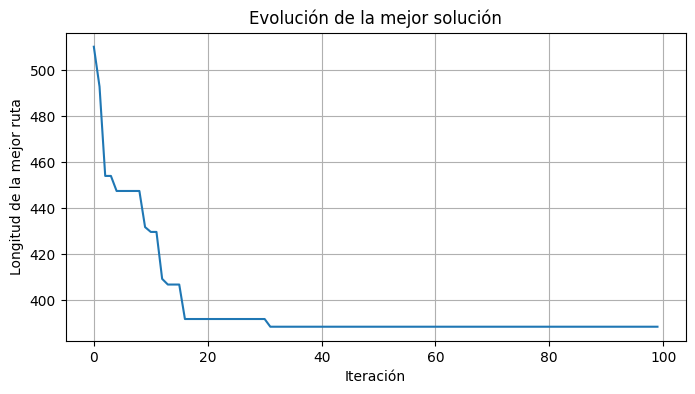

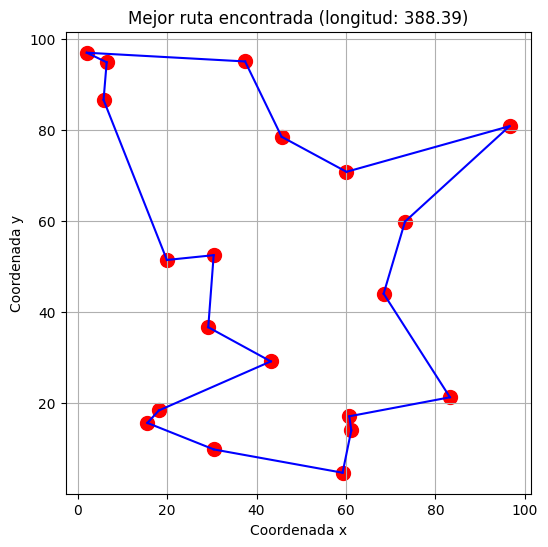

In [5]:
# Visualizar evolución de la solución
plt.figure(figsize=(8, 4))
plt.plot(historial)
plt.xlabel('Iteración')
plt.ylabel('Longitud de la mejor ruta')
plt.title('Evolución de la mejor solución')
plt.grid(True)
plt.show()

# Visualizar mejor ruta
visualizar_ruta(coordenadas, mejor_ruta,
               f"Mejor ruta encontrada (longitud: {mejor_longitud:.2f})")

La curva muestra la mejor longitud encontrada hasta cada iteración, de modo que nunca sube. Las mejoras se concentran en las primeras iteraciones, cuando la feromona todavía está repartida de forma casi uniforme y las hormigas exploran recorridos distintos. Después la feromona se acumula en unos pocos arcos y la colonia construye recorridos cada vez más parecidos entre sí. El recorrido final no tiene arcos que se crucen, que es lo que se espera de un buen recorrido en el plano euclidiano.

La matriz de feromonas al final de la corrida muestra esa concentración. Cada fila corresponde a una ciudad, y los valores altos marcan los arcos que la colonia terminó por preferir.

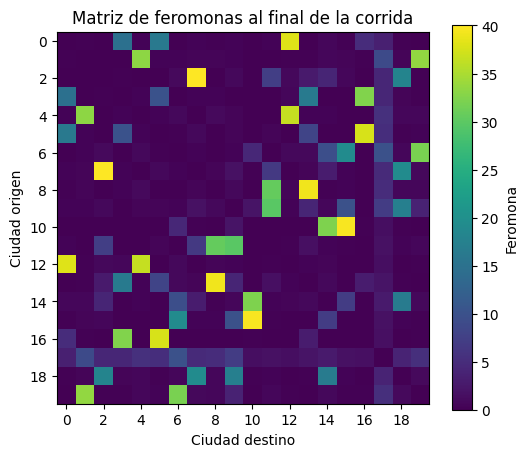

In [6]:
plt.figure(figsize=(6, 5))
plt.imshow(aco.feromonas, cmap='viridis')
plt.colorbar(label='Feromona')
plt.xlabel('Ciudad destino')
plt.ylabel('Ciudad origen')
plt.xticks(range(0, n_ciudades, 2))
plt.yticks(range(0, n_ciudades, 2))
plt.title('Matriz de feromonas al final de la corrida')
plt.show()

## El problema de la mochila y el ajuste de parámetros con Optuna

En el problema de la mochila (*knapsack problem*) hay $n$ objetos, cada uno con un peso $w_j$ y un valor $v_j$, y una mochila de capacidad $C$. Se busca el subconjunto de objetos de mayor valor total cuyo peso no supere la capacidad. La instancia tiene 50 objetos con pesos enteros entre 1 y 39, valores enteros entre 10 y 99, y una capacidad igual al 40 % de la suma de los pesos.

### Representación y construcción

Una solución es la lista de objetos que entran a la mochila. A diferencia del agente viajero, aquí la feromona no está en los arcos sino en los objetos, en un vector $\tau_j$ que empieza en 0,5. La información heurística es la razón entre valor y peso,

$$\eta_j = \frac{v_j}{w_j}.$$

Cada hormiga empieza con la mochila vacía y agrega objetos uno a uno. En cada paso solo considera los objetos $j$ que no ha elegido y que todavía caben, es decir, los del conjunto $F = \{ j : W + w_j \le C \}$, donde $W$ es el peso que ya lleva. Cuando $F$ queda vacío, la hormiga se detiene.

### Regla de transición con explotación y exploración

Esta versión usa la regla pseudoaleatoria proporcional (*pseudo-random proportional rule*). Con probabilidad $q_0$ la hormiga explota y toma el objeto que maximiza el producto de feromona y heurística:

$$j = \arg\max_{l \in F} \; \tau_l^{\alpha}\,\eta_l^{\beta}.$$

Con probabilidad $1-q_0$ explora y elige el objeto al azar con la misma regla proporcional del agente viajero:

$$p_j = \frac{\tau_j^{\alpha}\,\eta_j^{\beta}}{\sum_{l \in F} \tau_l^{\alpha}\,\eta_l^{\beta}}, \qquad j \in F.$$

### Evaporación, depósito y límites de la feromona

La evaporación es la misma, $\tau_j \leftarrow (1-\rho)\,\tau_j$. En el depósito, cada hormiga $k$ suma el valor total $V_k$ de su mochila a la feromona de cada objeto que eligió, sin dividir por ninguna constante:

$$\tau_j \leftarrow \tau_j + \sum_{k\,:\,j \in S_k} V_k,$$

donde $S_k$ es el conjunto de objetos de la hormiga $k$. Al final, la feromona se recorta al intervalo $[0{,}1;\ 2{,}0]$, para que ningún objeto quede con probabilidad nula ni domine por completo la selección.

In [7]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import optuna
from tqdm import tqdm

# Mensajes de Optuna solo en caso de advertencia, para que la salida sea legible
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

In [8]:
class ColoniaHormigasMochila:
    """
    Implementación del algoritmo de Colonia de Hormigas para el problema de la mochila.

    Args:
        pesos (list): Lista de pesos de los objetos
        valores (list): Lista de valores de los objetos
        capacidad (int): Capacidad máxima de la mochila
        n_hormigas (int): Número de hormigas en la colonia
        alpha (float): Importancia de las feromonas
        beta (float): Importancia de la información heurística
        rho (float): Tasa de evaporación de feromonas
        q0 (float): Parámetro de exploración vs explotación
        max_iter (int): Número máximo de iteraciones
    """

    def __init__(self, pesos, valores, capacidad, n_hormigas=10, alpha=1.0,
                 beta=2.0, rho=0.1, q0=0.9, max_iter=100):
        self.pesos = pesos
        self.valores = valores
        self.capacidad = capacidad
        self.n_objetos = len(pesos)
        self.n_hormigas = n_hormigas
        self.alpha = alpha
        self.beta = beta
        self.rho = rho
        self.q0 = q0
        self.max_iter = max_iter

        # Inicializar feromonas
        self.feromonas = np.ones(self.n_objetos) * 0.5

        # Calcular heurística (valor/peso)
        self.heuristica = np.array([v/w for v, w in zip(valores, pesos)])

    def seleccionar_objeto(self, objetos_disponibles, peso_actual):
        """Selecciona un objeto usando la regla de transición"""
        if not objetos_disponibles:
            return None

        # Filtrar objetos que caben en la mochila
        objetos_validos = [obj for obj in objetos_disponibles
                          if peso_actual + self.pesos[obj] <= self.capacidad]

        if not objetos_validos:
            return None

        # Decidir entre exploración y explotación
        if np.random.random() < self.q0:
            # Explotación: elegir el mejor objeto según la regla
            productos = [(self.feromonas[obj]**self.alpha) *
                         (self.heuristica[obj]**self.beta) for obj in objetos_validos]
            return objetos_validos[np.argmax(productos)]
        else:
            # Exploración: selección probabilística
            productos = [(self.feromonas[obj]**self.alpha) *
                         (self.heuristica[obj]**self.beta) for obj in objetos_validos]
            suma = sum(productos)
            probabilidades = [p/suma for p in productos]
            return np.random.choice(objetos_validos, p=probabilidades)

    def construir_solucion(self):
        """Construye una solución para una hormiga"""
        solucion = []
        objetos_disponibles = list(range(self.n_objetos))
        peso_actual = 0

        while objetos_disponibles:
            obj = self.seleccionar_objeto(objetos_disponibles, peso_actual)
            if obj is None:
                break

            solucion.append(obj)
            peso_actual += self.pesos[obj]
            objetos_disponibles.remove(obj)

        valor_total = sum(self.valores[obj] for obj in solucion)
        return solucion, valor_total, peso_actual

    def actualizar_feromonas(self, soluciones, valores):
        """Actualiza los niveles de feromonas"""
        # Evaporación
        self.feromonas *= (1 - self.rho)

        # Depósito de nuevas feromonas
        for solucion, valor in zip(soluciones, valores):
            for obj in solucion:
                self.feromonas[obj] += valor

        # Limitar feromonas para evitar estancamiento
        self.feromonas = np.clip(self.feromonas, 0.1, 2.0)

    def optimizar(self):
        """Ejecuta el algoritmo de optimización"""
        mejor_solucion = None
        mejor_valor = 0
        historial_valores = []

        for _ in range(self.max_iter):
            soluciones = []
            valores = []
            pesos = []

            for _ in range(self.n_hormigas):
                solucion, valor, peso = self.construir_solucion()
                soluciones.append(solucion)
                valores.append(valor)
                pesos.append(peso)

                if valor > mejor_valor:
                    mejor_valor = valor
                    mejor_solucion = solucion.copy()
                    mejor_peso = peso

            self.actualizar_feromonas(soluciones, valores)
            historial_valores.append(mejor_valor)

        return mejor_solucion, mejor_valor, mejor_peso, historial_valores

La función `generar_problema_mochila` crea la instancia con una semilla fija, y las variables globales `pesos_global`, `valores_global` y `capacidad_global` la dejan disponible para la función objetivo de Optuna.

In [9]:
def generar_problema_mochila(n_objetos=50, seed=123456789):
    """Genera un problema de la mochila aleatorio"""
    np.random.seed(seed)
    pesos = np.random.randint(1, 40, size=n_objetos)
    valores = np.random.randint(10, 100, size=n_objetos)
    capacidad = int(sum(pesos) * 0.4)  # 40% de la suma total de pesos
    return pesos, valores, capacidad

# Variables globales para el problema (necesarias para Optuna)
pesos_global, valores_global, capacidad_global = generar_problema_mochila(n_objetos=50)

### Ajuste de parámetros con Optuna

El desempeño de la colonia depende de cinco parámetros: el número de hormigas, $\alpha$, $\beta$, $\rho$ y $q_0$. El código los ajusta con Optuna, una biblioteca que propone configuraciones, las evalúa con una función objetivo y usa los resultados para proponer las siguientes. Aquí la función objetivo corre la colonia con 50 iteraciones y devuelve el mejor valor de la mochila, que Optuna maximiza. El muestreador es TPE (*Tree-structured Parzen Estimator*) con semilla fija. El capítulo 9 trata a fondo el ajuste de hiperparámetros; en este capítulo basta con ver el procedimiento aplicado a la colonia.

Los intervalos de búsqueda son los siguientes:

- número de hormigas, entero entre 5 y 50;
- $\alpha$ entre 0,1 y 3,0;
- $\beta$ entre 0,1 y 5,0;
- $\rho$ entre 0,01 y 0,5;
- $q_0$ entre 0,5 y 0,99.

In [10]:
def objetivo_optuna(trial):
    """Función objetivo para Optuna"""
    # Parámetros a optimizar
    n_hormigas = trial.suggest_int('n_hormigas', 5, 50)
    alpha = trial.suggest_float('alpha', 0.1, 3.0)
    beta = trial.suggest_float('beta', 0.1, 5.0)
    rho = trial.suggest_float('rho', 0.01, 0.5)
    q0 = trial.suggest_float('q0', 0.5, 0.99)

    # Crear y ejecutar el algoritmo con estos parámetros
    aco = ColoniaHormigasMochila(
        pesos=pesos_global,
        valores=valores_global,
        capacidad=capacidad_global,
        n_hormigas=n_hormigas,
        alpha=alpha,
        beta=beta,
        rho=rho,
        q0=q0,
        max_iter=50  # Reducimos iteraciones para la optimización
    )

    _, valor, _, _ = aco.optimizar()
    return valor  # Maximizar el valor

def ejecutar_con_parametros(params):
    """Ejecuta el algoritmo con un conjunto de parámetros"""
    aco = ColoniaHormigasMochila(
        pesos=pesos_global,
        valores=valores_global,
        capacidad=capacidad_global,
        **params
    )
    _, valor, _, historial = aco.optimizar()
    return valor, historial

# Optimización de hiperparámetros con Optuna
def optimizar_hiperparametros(n_trials=100):
    print("Iniciando optimización de hiperparámetros con Optuna...")

    # Asegurarse de que haya al menos 20 trials para un análisis estadístico significativo
    if n_trials < 20:
        print("Advertencia: Se recomienda al menos 20 trials para un análisis estadístico significativo.")
        print(f"Continuando con {n_trials} trials...")

    # Crear un estudio con un sampler que garantice diversidad
    sampler = optuna.samplers.TPESampler(seed=42)
    estudio = optuna.create_study(direction='maximize', sampler=sampler)

    # Ejecutar la optimización
    estudio.optimize(objetivo_optuna, n_trials=n_trials)

    print("\nMejores hiperparámetros encontrados:")
    print(f"Valor máximo: {estudio.best_value}")
    for param, valor in estudio.best_params.items():
        print(f"{param}: {valor}")

    return estudio

Una vez terminado el estudio, `comparar_configuraciones` corre la colonia con 100 iteraciones y cuatro configuraciones: la que el código toma por defecto, la mejor que encontró Optuna y las dos siguientes en el escalafón de pruebas. En el script original estas corridas se repartían entre varios procesos; en el cuaderno se ejecutan una tras otra.

In [11]:
# Comparación de diferentes configuraciones
def comparar_configuraciones(estudio, n_configuraciones=3):
    print("\nComparando diferentes configuraciones...")

    # Configuración por defecto
    config_default = {
        'n_hormigas': 10,
        'alpha': 1.0,
        'beta': 2.0,
        'rho': 0.1,
        'q0': 0.9,
        'max_iter': 100
    }

    # Mejor configuración encontrada por Optuna
    config_optuna = {
        'n_hormigas': estudio.best_params['n_hormigas'],
        'alpha': estudio.best_params['alpha'],
        'beta': estudio.best_params['beta'],
        'rho': estudio.best_params['rho'],
        'q0': estudio.best_params['q0'],
        'max_iter': 100
    }

    # Otras configuraciones de los mejores trials
    otras_configs = []
    for i in range(1, n_configuraciones):
        if i < len(estudio.trials):
            trial = sorted(estudio.trials, key=lambda t: t.value, reverse=True)[i]
            config = {
                'n_hormigas': trial.params['n_hormigas'],
                'alpha': trial.params['alpha'],
                'beta': trial.params['beta'],
                'rho': trial.params['rho'],
                'q0': trial.params['q0'],
                'max_iter': 100
            }
            otras_configs.append(config)

    # Ejecutar todas las configuraciones
    configs = [config_default, config_optuna] + otras_configs
    nombres = ["Por defecto", "Mejor de Optuna"] + [f"Configuración {i+1}" for i in range(len(otras_configs))]

    resultados = []
    historiales = []

    # Ejecución secuencial (en un cuaderno, ProcessPoolExecutor no puede
    # serializar funciones definidas en el propio cuaderno)
    for resultado in map(ejecutar_con_parametros, configs):
        valor, historial = resultado
        resultados.append(valor)
        historiales.append(historial)

    # Visualizar resultados
    visualizar_comparacion(nombres, resultados, historiales)
    return configs, nombres, resultados, historiales

def visualizar_comparacion(nombres, resultados, historiales):
    """Visualiza la comparación entre diferentes configuraciones"""
    # Gráfico de barras para valores finales
    plt.figure(figsize=(8, 4))
    plt.bar(nombres, resultados, color=['blue', 'green'] + ['orange'] * (len(nombres)-2))
    plt.title('Comparación del valor final por configuración')
    plt.xlabel('Configuración')
    plt.ylabel('Valor final')
    for i, v in enumerate(resultados):
        plt.text(i, v + 5, f"{v}", ha='center')
    plt.tight_layout()
    plt.show()

    # Gráfico de líneas para convergencia
    plt.figure(figsize=(8, 4))
    for i, historial in enumerate(historiales):
        plt.plot(historial, label=nombres[i])
    plt.title('Convergencia por configuración')
    plt.xlabel('Iteración')
    plt.ylabel('Mejor valor')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

La función `visualizar_importancia_parametros` usa las gráficas de Optuna para estimar cuánto influye cada parámetro en el valor obtenido y para ver cómo cambia el valor en dos planos de parámetros.

In [12]:
def visualizar_importancia_parametros(estudio):
    """Visualiza la importancia de los parámetros"""
    try:
        ax = optuna.visualization.matplotlib.plot_param_importances(estudio)
        ax.figure.set_size_inches(8, 4)
        ax.set_title('', loc='left')
        ax.set_title('Importancia de los hiperparámetros')
        ax.set_xlabel('Importancia relativa')
        ax.set_ylabel('Hiperparámetro')
        ax.get_legend().remove() if ax.get_legend() else None
        plt.tight_layout()
        plt.show()
    except RuntimeError as e:
        print(f"No se pudo calcular la importancia de parámetros con FANOVA: {e}")
        print("Esto puede ocurrir si hay poca variación en los resultados o pocos trials.")
        print("Continuando con las otras visualizaciones...")

    try:
        ax = optuna.visualization.matplotlib.plot_contour(estudio, params=['alpha', 'beta'])
        ax.figure.set_size_inches(7, 5)
        ax.set_title('Contorno de optimización: alpha frente a beta')
        ax.figure.axes[-1].set_ylabel('Valor de la mochila')
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"No se pudo generar el contorno Alpha vs Beta: {e}")

    try:
        ax = optuna.visualization.matplotlib.plot_contour(estudio, params=['n_hormigas', 'rho'])
        ax.figure.set_size_inches(7, 5)
        ax.set_title('Contorno: número de hormigas frente a tasa de evaporación')
        ax.figure.axes[-1].set_ylabel('Valor de la mochila')
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"No se pudo generar el contorno Número de Hormigas vs Tasa de Evaporación: {e}")

### Resultados

La celda siguiente corre el procedimiento completo, que en el script original estaba en la función `ejecutar_demo`.

In [13]:
random.seed(42)
np.random.seed(42)

print("Problema de la Mochila:")
print(f"Número de objetos: {len(pesos_global)}")
print(f"Capacidad de la mochila: {capacidad_global}")

# Optimizar hiperparámetros
inicio = time.time()
N_PRUEBAS = 100
estudio = optimizar_hiperparametros(n_trials=N_PRUEBAS)
fin = time.time()
print(f"\nTiempo de optimización: {fin-inicio:.2f} segundos")

Problema de la Mochila:
Número de objetos: 50
Capacidad de la mochila: 437
Iniciando optimización de hiperparámetros con Optuna...



Mejores hiperparámetros encontrados:
Valor máximo: 1456.0
n_hormigas: 33
alpha: 0.5045321958909214
beta: 1.5315087778225691
rho: 0.18951730321390894
q0: 0.7234742922663476

Tiempo de optimización: 33.99 segundos



Comparando diferentes configuraciones...


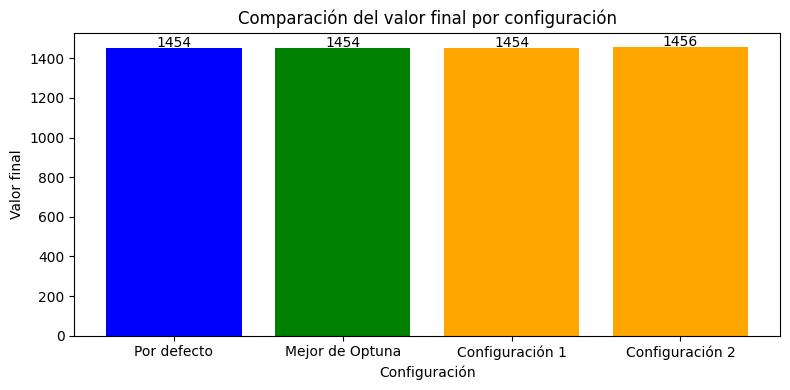

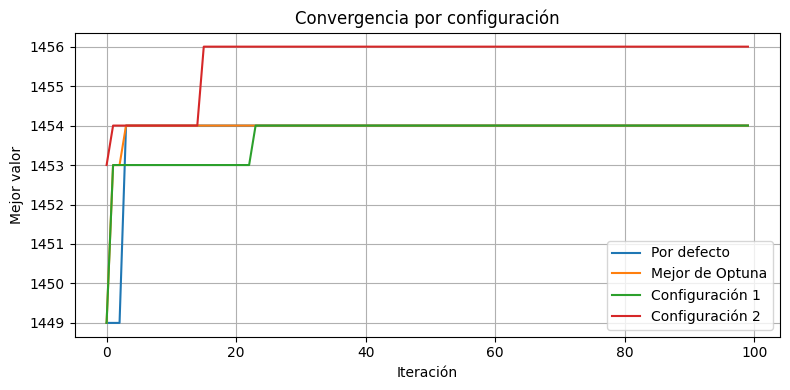

In [14]:
# Comparar configuraciones
configs, nombres, resultados, historiales = comparar_configuraciones(estudio)

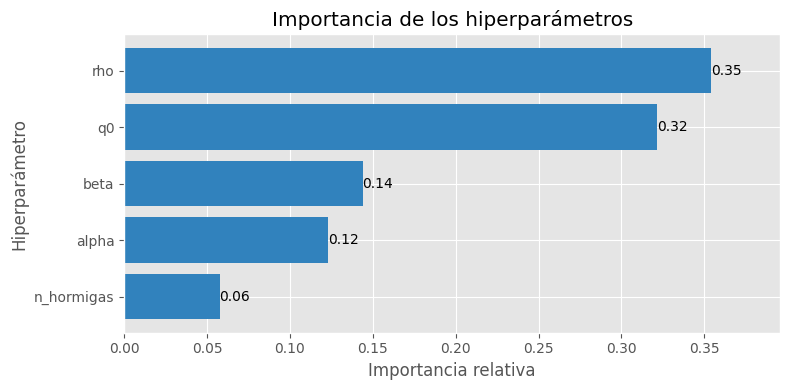

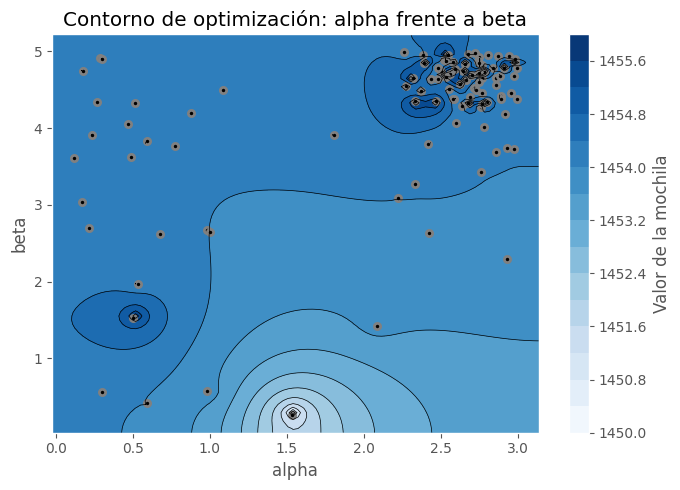

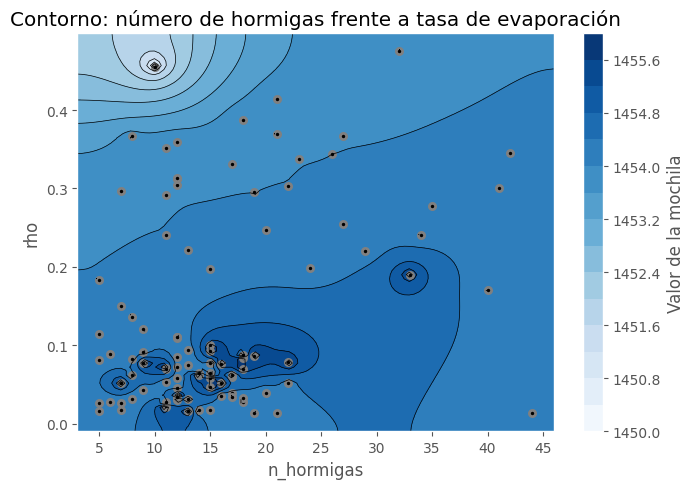


Mejor configuración: Configuración 2
n_hormigas: 17
alpha: 2.559657014357323
beta: 4.709132372523028
rho: 0.05934490833864177
q0: 0.5045975884866636
max_iter: 100
Valor obtenido: 1456


In [15]:
# Visualizar importancia de parámetros
visualizar_importancia_parametros(estudio)
plt.style.use('default')  # las gráficas de Optuna dejan activo el estilo ggplot

# Mostrar detalles de la mejor configuración
mejor_idx = resultados.index(max(resultados))
print(f"\nMejor configuración: {nombres[mejor_idx]}")
for param, valor in configs[mejor_idx].items():
    print(f"{param}: {valor}")
print(f"Valor obtenido: {resultados[mejor_idx]}")

En esta instancia las cuatro configuraciones terminan a muy pocas unidades unas de otras, y todas alcanzan su mejor valor antes de la iteración 25. La configuración que Optuna marcó como la mejor tampoco repite exactamente el valor que obtuvo durante el estudio: allí corrió con 50 iteraciones y otra secuencia de números aleatorios, y una sola corrida de un algoritmo estocástico no basta para ordenar configuraciones cuyas diferencias son tan pequeñas. El capítulo 10 trata la comparación estadística de algoritmos, que es la herramienta para esa pregunta.

La gráfica de importancia indica a qué parámetros respondió más el valor dentro de los intervalos explorados; en este estudio, la tasa de evaporación y $q_0$ encabezan la lista. Los contornos muestran dónde concentró TPE sus pruebas, que es la región en que el muestreador encontró los mejores valores y a la que vuelve una y otra vez.

## Asignación de recursos en un entorno cambiante

El tercer ejemplo asigna $m$ recursos a $T$ tareas, con a lo sumo una tarea por recurso, y busca maximizar el beneficio total. El beneficio $b_{rt}$ de asignar el recurso $r$ a la tarea $t$ cambia de una iteración a otra, de modo que el algoritmo optimiza sobre un problema que se mueve. En la instancia hay 10 recursos y 5 tareas, y los beneficios iniciales son uniformes entre 0 y 100.

### Dinámica de los beneficios

Al comienzo de la iteración $t$, cada beneficio recibe una perturbación y luego se recorta al intervalo $[0, 100]$:

$$b_{rt} \leftarrow \min\{100,\ \max\{0,\ b_{rt} + 20\,\sin(t/10)\,u_{rt}\}\},$$

donde cada $u_{rt}$ es uniforme entre 0 y 1. El seno hace que durante unas iteraciones los beneficios tiendan a subir y durante otras tiendan a bajar.

### Representación y reglas

Una solución es una lista de pares (recurso, tarea). La hormiga recorre las tareas en orden y, para cada una, elige un recurso entre los que siguen libres. La feromona $\tau_{rt}$ vive en los pares recurso-tarea y empieza en 0,1. La información heurística es el beneficio normalizado por el mayor beneficio actual,

$$\eta_{rt} = \frac{b_{rt}}{\max_{r',t'} b_{r't'}},$$

que se recalcula en cada iteración porque los beneficios cambian. Si $R$ es el conjunto de recursos libres, la probabilidad de asignar el recurso $r$ a la tarea $t$ es

$$p_{rt} = \frac{\tau_{rt}^{\alpha}\,\eta_{rt}^{\beta}}{\sum_{l \in R} \tau_{lt}^{\alpha}\,\eta_{lt}^{\beta}}.$$

Tras la evaporación, cada hormiga $k$ con beneficio total $B_k$ deposita $Q\,B_k$ en cada par que usó:

$$\tau_{rt} \leftarrow (1-\rho)\,\tau_{rt} + \sum_{k\,:\,(r,t) \in A_k} Q\,B_k.$$

In [16]:
class ColoniaHormigasOptimizador:
    """
    Implementación del algoritmo de Colonia de Hormigas para un problema dinámico de optimización.
    En este caso, optimizaremos la asignación de recursos en un entorno cambiante.

    Args:
        n_recursos (int): Número de recursos disponibles
        n_tareas (int): Número de tareas a realizar
        n_hormigas (int): Número de hormigas en la colonia
        alpha (float): Importancia de las feromonas (α)
        beta (float): Importancia de la información heurística (β)
        rho (float): Tasa de evaporación de feromonas (ρ)
        Q (float): Constante de depósito de feromonas
    """

    def __init__(self, n_recursos=10, n_tareas=5, n_hormigas=20, alpha=1.0, beta=2.0, rho=0.1, Q=100):
        self.n_recursos = n_recursos
        self.n_tareas = n_tareas
        self.n_hormigas = n_hormigas
        self.alpha = alpha
        self.beta = beta
        self.rho = rho
        self.Q = Q

        # Matriz de feromonas entre recursos y tareas
        self.feromonas = np.ones((n_recursos, n_tareas)) * 0.1

        # Matriz de beneficios dinámicos (cambia con el tiempo)
        self.beneficios = self.generar_beneficios_iniciales()

    def generar_beneficios_iniciales(self):
        """Genera matriz inicial de beneficios aleatorios"""
        return np.random.rand(self.n_recursos, self.n_tareas) * 100

    def actualizar_beneficios(self, iteracion):
        """Actualiza los beneficios de forma dinámica según la iteración"""
        perturbacion = np.sin(iteracion/10) * np.random.rand(self.n_recursos, self.n_tareas) * 20
        self.beneficios += perturbacion
        self.beneficios = np.clip(self.beneficios, 0, 100)

    def calcular_visibilidad(self):
        """Calcula la matriz de visibilidad basada en los beneficios actuales"""
        # Ajuste para el cuaderno: si todos los beneficios llegan a cero, se evita
        # la división 0/0 (en el script original produce NaN y detiene la corrida)
        return self.beneficios / max(np.max(self.beneficios), 1e-12)

    def construir_solucion(self, visibilidad):
        """
        Construye una solución asignando recursos a tareas.

        Returns:
            tuple: (asignaciones, beneficio_total)
        """
        asignaciones = []
        recursos_disponibles = list(range(self.n_recursos))

        for tarea in range(self.n_tareas):
            if not recursos_disponibles:
                break

            # Calcular probabilidades de selección
            probabilidades = np.zeros(len(recursos_disponibles))
            for i, recurso in enumerate(recursos_disponibles):
                tau = self.feromonas[recurso, tarea]
                eta = visibilidad[recurso, tarea]
                probabilidades[i] = (tau ** self.alpha) * (eta ** self.beta)

            # Ajuste para el cuaderno: si todos los productos son cero, elección uniforme
            if np.sum(probabilidades) == 0:
                probabilidades = np.ones(len(recursos_disponibles))
            probabilidades = probabilidades / np.sum(probabilidades)

            # Seleccionar recurso
            recurso_idx = np.random.choice(len(recursos_disponibles), p=probabilidades)
            recurso = recursos_disponibles.pop(recurso_idx)
            asignaciones.append((recurso, tarea))

        # Calcular beneficio total
        beneficio_total = sum(self.beneficios[r,t] for r,t in asignaciones)
        return asignaciones, beneficio_total

    def optimizar(self, max_iter=100):
        """
        Ejecuta el algoritmo de optimización.

        Returns:
            tuple: (mejor_asignacion, mejor_beneficio, historial_beneficios)
        """
        mejor_asignacion = None
        mejor_beneficio = 0
        historial_beneficios = []

        for iteracion in range(max_iter):
            # Actualizar beneficios dinámicamente
            self.actualizar_beneficios(iteracion)
            visibilidad = self.calcular_visibilidad()

            # Construir soluciones con todas las hormigas
            soluciones = []
            beneficios = []
            for _ in range(self.n_hormigas):
                asignacion, beneficio = self.construir_solucion(visibilidad)
                soluciones.append(asignacion)
                beneficios.append(beneficio)

                if beneficio > mejor_beneficio:
                    mejor_beneficio = beneficio
                    mejor_asignacion = asignacion.copy()

            # Actualizar feromonas
            self.feromonas *= (1 - self.rho)  # Evaporación

            for asignacion, beneficio in zip(soluciones, beneficios):
                for recurso, tarea in asignacion:
                    self.feromonas[recurso, tarea] += self.Q * beneficio

            historial_beneficios.append(mejor_beneficio)

        return mejor_asignacion, mejor_beneficio, historial_beneficios

def visualizar_resultados(historial_beneficios, titulo="Evolución del beneficio"):
    """Visualiza la evolución del beneficio durante la optimización"""
    plt.figure(figsize=(8, 4))
    plt.plot(historial_beneficios)
    plt.xlabel('Iteración')
    plt.ylabel('Mejor beneficio')
    plt.title(titulo)
    plt.grid(True)
    plt.show()

### Resultados

Mejor beneficio encontrado: 500.00
Mejor asignación de recursos a tareas:
Recurso 5 -> Tarea 0
Recurso 2 -> Tarea 1
Recurso 1 -> Tarea 2
Recurso 8 -> Tarea 3
Recurso 6 -> Tarea 4


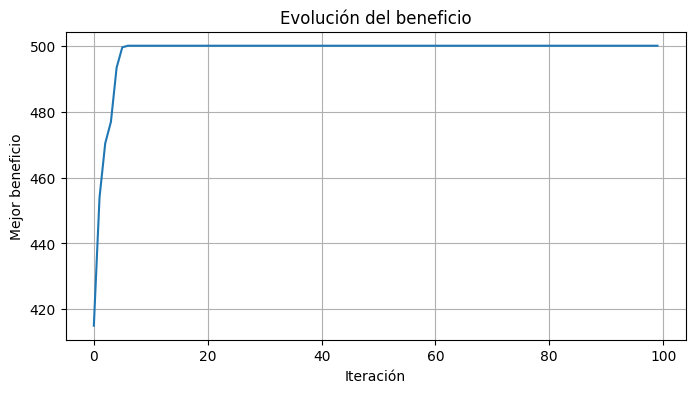

In [17]:
random.seed(42)
np.random.seed(42)

# Crear y ejecutar el optimizador
aco = ColoniaHormigasOptimizador(n_recursos=10, n_tareas=5)
mejor_asignacion, mejor_beneficio, historial = aco.optimizar(max_iter=100)

# Mostrar resultados
print(f"Mejor beneficio encontrado: {mejor_beneficio:.2f}")
print("Mejor asignación de recursos a tareas:")
for recurso, tarea in mejor_asignacion:
    print(f"Recurso {recurso} -> Tarea {tarea}")

# Visualizar evolución
visualizar_resultados(historial)

El mejor beneficio llega pronto a 500, el máximo posible, pues hay cinco tareas y cada beneficio está acotado por 100. La curva es la del mejor beneficio registrado hasta cada iteración, de modo que no baja aunque el entorno cambie. Como la perturbación se acumula y el seno es positivo durante las primeras 32 iteraciones, en ese tramo los beneficios solo pueden subir y se acercan al tope de 100; en el tramo siguiente, con el seno negativo, bajan hacia cero. El mejor beneficio registrado corresponde, entonces, a los beneficios de una iteración temprana, y la asignación que se imprime puede no ser buena para los beneficios de la última iteración.

Cuando todos los beneficios valen cero, la visibilidad también es cero y la regla de transición no está definida; para que la corrida no se detenga, el código del cuaderno elige en ese caso el recurso de manera uniforme.

## Selección de variables para un clasificador

En este ejemplo la colonia escoge un subconjunto de las 30 variables del conjunto de datos de cáncer de mama de Wisconsin, que trae scikit-learn, para clasificar los tumores en malignos y benignos con un bosque aleatorio (*random forest*). La calidad de un subconjunto es la exactitud (*accuracy*) del bosque entrenado solo con esas variables, medida sobre un 20 % de los datos que se separa al comienzo.

### Representación y reglas

Una solución es la lista de índices de las variables elegidas. La feromona es un vector $\tau_j$ que empieza en 0,1. La información heurística $\eta_j$ es la importancia de la variable $j$ según un bosque aleatorio entrenado con todas las variables. La hormiga calcula

$$p_j = \frac{\tau_j^{\alpha}\,\eta_j^{\beta}}{\sum_{l=1}^{30} \tau_l^{\alpha}\,\eta_l^{\beta}}$$

y luego recorre las variables una a una e incluye la variable $j$ con probabilidad $p_j$, de forma independiente de las demás. Si al final no eligió ninguna, toma una al azar. Como las $p_j$ suman uno, el número esperado de variables elegidas por una hormiga es uno.

Tras la evaporación, cada hormiga $k$ deposita $Q$ veces su exactitud $a_k$ en cada variable que eligió:

$$\tau_j \leftarrow (1-\rho)\,\tau_j + \sum_{k\,:\,j \in S_k} Q\,a_k.$$

In [18]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier

class ColoniaHormigasSeleccionVariables:
    """
    Implementación del algoritmo de Colonia de Hormigas para selección de variables
    en un problema de clasificación.

    Args:
        X (np.array): Matriz de características
        y (np.array): Vector de etiquetas
        n_hormigas (int): Número de hormigas en la colonia
        alpha (float): Importancia de las feromonas
        beta (float): Importancia de la información heurística
        rho (float): Tasa de evaporación de feromonas
        Q (float): Constante de depósito de feromonas
    """

    def __init__(self, X, y, n_hormigas=20, alpha=1.0, beta=2.0, rho=0.1, Q=1.0):
        self.X = X
        self.y = y
        self.n_variables = X.shape[1]
        self.n_hormigas = n_hormigas
        self.alpha = alpha
        self.beta = beta
        self.rho = rho
        self.Q = Q

        # Inicializar feromonas
        self.feromonas = np.ones(self.n_variables) * 0.1

        # Dividir datos en entrenamiento y prueba
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            X, y, test_size=0.2, random_state=42)

    def calcular_visibilidad(self):
        """Calcula la importancia de cada variable usando Random Forest"""
        rf = RandomForestClassifier(n_estimators=100, random_state=42)
        rf.fit(self.X_train, self.y_train)
        return rf.feature_importances_

    def construir_solucion(self, visibilidad):
        """
        Construye una solución seleccionando variables.

        Returns:
            tuple: (variables_seleccionadas, accuracy)
        """
        variables_seleccionadas = []
        probabilidades = (self.feromonas ** self.alpha) * (visibilidad ** self.beta)
        probabilidades = probabilidades / np.sum(probabilidades)

        # Seleccionar variables aleatoriamente según probabilidades
        for i in range(self.n_variables):
            if np.random.random() < probabilidades[i]:
                variables_seleccionadas.append(i)

        if not variables_seleccionadas:
            # Asegurar que al menos una variable sea seleccionada
            variables_seleccionadas.append(np.random.randint(self.n_variables))

        # Evaluar solución
        accuracy = self.evaluar_solucion(variables_seleccionadas)
        return variables_seleccionadas, accuracy

    def evaluar_solucion(self, variables):
        """Evalúa la calidad de la selección de variables usando Random Forest"""
        if len(variables) == 0:
            return 0.0

        X_train_sel = self.X_train[:, variables]
        X_test_sel = self.X_test[:, variables]

        rf = RandomForestClassifier(n_estimators=100, random_state=42)
        rf.fit(X_train_sel, self.y_train)
        y_pred = rf.predict(X_test_sel)
        return accuracy_score(self.y_test, y_pred)

    def optimizar(self, max_iter=50):
        """
        Ejecuta el algoritmo de optimización.

        Returns:
            tuple: (mejores_variables, mejor_accuracy, historial_accuracy)
        """
        mejor_solucion = None
        mejor_accuracy = 0
        historial_accuracy = []

        for iteracion in range(max_iter):
            visibilidad = self.calcular_visibilidad()

            # Construir soluciones con todas las hormigas
            soluciones = []
            accuracies = []

            for _ in range(self.n_hormigas):
                variables, accuracy = self.construir_solucion(visibilidad)
                soluciones.append(variables)
                accuracies.append(accuracy)

                if accuracy > mejor_accuracy:
                    mejor_accuracy = accuracy
                    mejor_solucion = variables.copy()

            # Actualizar feromonas
            self.feromonas *= (1 - self.rho)  # Evaporación

            for variables, accuracy in zip(soluciones, accuracies):
                for var in variables:
                    self.feromonas[var] += self.Q * accuracy

            historial_accuracy.append(mejor_accuracy)

        return mejor_solucion, mejor_accuracy, historial_accuracy

### Resultados

Mejores variables seleccionadas:
- mean concave points
- worst area
- worst concave points

Mejor accuracy: 0.9561
Número de variables seleccionadas: 3


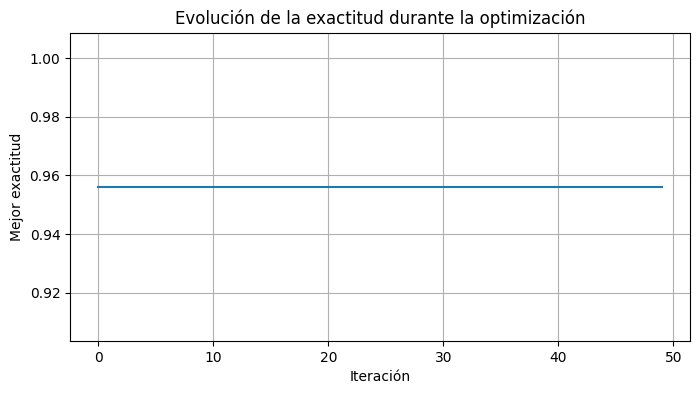

In [19]:
random.seed(42)
np.random.seed(42)

# Cargar dataset de cáncer de mama
data = load_breast_cancer()
X, y = data.data, data.target

# Crear y ejecutar optimizador
aco = ColoniaHormigasSeleccionVariables(X, y)
mejores_variables, mejor_accuracy, historial = aco.optimizar(max_iter=50)

# Mostrar resultados
print("Mejores variables seleccionadas:")
for var in mejores_variables:
    print(f"- {data.feature_names[var]}")
print(f"\nMejor accuracy: {mejor_accuracy:.4f}")
print(f"Número de variables seleccionadas: {len(mejores_variables)}")

# Visualizar evolución
plt.figure(figsize=(8, 4))
plt.plot(historial)
plt.xlabel('Iteración')
plt.ylabel('Mejor exactitud')
plt.title('Evolución de la exactitud durante la optimización')
plt.grid(True)
plt.show()

La mejor exactitud aparece en la primera iteración y no cambia en el resto de la corrida, con un subconjunto de pocas variables. Esto es coherente con la regla de construcción: como el número esperado de variables por hormiga es uno, la colonia explora sobre todo subconjuntos muy pequeños, y la feromona refuerza las variables a las que el bosque aleatorio ya asignaba más importancia. La exactitud se mide sobre el mismo 20 % de datos que guía la búsqueda, de modo que es una estimación optimista del desempeño del subconjunto elegido con datos nuevos.

## Política de inventario con demanda estocástica

El último ejemplo lleva la colonia a un problema de decisión secuencial. En cada periodo se observa el inventario y se decide cuánto pedir; luego llega una demanda aleatoria. El objetivo es minimizar el costo acumulado, que se expresa como una recompensa negativa, en el lenguaje del aprendizaje por refuerzo (*reinforcement learning*). Aquí la colonia no construye una secuencia de pedidos sino una política (*policy*), una regla que dice cuánto pedir según el nivel de inventario.

### El entorno

La clase `EntornoInventario` sigue la interfaz de Gymnasium, con los métodos `reset` y `step`. Sus elementos son los siguientes:

- la capacidad del almacén es de 100 unidades y el inventario inicial, de 50;
- la demanda de cada periodo es la parte entera de una normal con media 30 y desviación 10, truncada en cero;
- la acción $a \in \{0, 1, \dots, 10\}$ equivale a pedir $10a$ unidades;
- los pedidos se guardan en una cola con un tiempo de entrega, y al recibirlos el inventario no puede pasar de la capacidad;
- el costo del periodo es un costo fijo de 10 si se pide algo, más 1 por unidad en inventario antes de atender la demanda, más 5 por unidad faltante.

La recompensa del periodo es el negativo de ese costo.

In [20]:
import gymnasium as gym
from gymnasium import spaces
from collections import defaultdict

class EntornoInventario(gym.Env):
    """
    Entorno de simulación para un problema de gestión de inventario
    con demanda estocástica.
    """
    def __init__(self, capacidad_max=100, demanda_media=30, demanda_std=10,
                 costo_pedido=10, costo_mantenimiento=1, costo_faltante=5,
                 lead_time=0):
        super().__init__()

        # Parámetros del problema
        self.capacidad_max = capacidad_max
        self.demanda_media = demanda_media
        self.demanda_std = demanda_std
        self.costo_pedido = costo_pedido
        self.costo_mantenimiento = costo_mantenimiento
        self.costo_faltante = costo_faltante
        self.lead_time = lead_time

        # Espacio de observación: [inventario_actual, pedidos_pendientes, demanda_previa]
        self.observation_space = spaces.Box(
            low=np.array([0, 0, 0]),
            high=np.array([capacidad_max, capacidad_max, capacidad_max*2]),
            dtype=np.float32
        )

        # Espacio de acciones: cantidad a pedir (discretizado)
        self.n_acciones = 11  # 0, 10, 20, ..., 100
        self.action_space = spaces.Discrete(self.n_acciones)

        # Cola de pedidos pendientes
        self.pedidos_pendientes = []

        # Inicializar estado
        self.reset()

    def _generar_demanda(self):
        """Genera una demanda aleatoria según distribución normal truncada"""
        demanda = int(np.random.normal(self.demanda_media, self.demanda_std))
        return max(0, demanda)  # La demanda no puede ser negativa

    def reset(self, seed=None, options=None):
        """Reinicia el entorno al estado inicial"""
        super().reset(seed=seed)
        self.inventario = self.capacidad_max // 2  # Comenzamos con inventario medio
        self.pedidos_pendientes = []
        self.demanda_previa = self._generar_demanda()  # Información de la última demanda
        self.periodo = 0

        return np.array([self.inventario, sum(self.pedidos_pendientes), self.demanda_previa]), {}

    def step(self, action):
        """
        Ejecuta un paso en el entorno

        Args:
            action (int): Índice de la acción (0-10) que representa la cantidad a pedir

        Returns:
            tuple: (observación, recompensa, terminado, truncado, info)
        """
        # Convertir acción discreta a cantidad a pedir
        cantidad_pedido = action * (self.capacidad_max // 10)

        # Recibir pedidos pendientes (si hay)
        if self.pedidos_pendientes and self.pedidos_pendientes[0][1] <= 0:
            pedido_recibido = self.pedidos_pendientes.pop(0)[0]
            self.inventario = min(self.inventario + pedido_recibido, self.capacidad_max)

        # Actualizar tiempos de entrega de pedidos pendientes
        for i in range(len(self.pedidos_pendientes)):
            self.pedidos_pendientes[i] = (self.pedidos_pendientes[i][0], self.pedidos_pendientes[i][1] - 1)

        # Añadir nuevo pedido a la cola si es mayor que cero
        if cantidad_pedido > 0:
            self.pedidos_pendientes.append((cantidad_pedido, self.lead_time))

        # Generar demanda para este período
        demanda = self._generar_demanda()

        # Calcular costos
        costo_pedido = self.costo_pedido * (1 if cantidad_pedido > 0 else 0)
        costo_mantenimiento = self.costo_mantenimiento * self.inventario

        # Actualizar inventario después de la demanda
        inventario_previo = self.inventario
        self.inventario = max(0, self.inventario - demanda)
        faltante = max(0, demanda - inventario_previo)
        costo_faltante = self.costo_faltante * faltante

        # Costo total (recompensa negativa)
        costo_total = costo_pedido + costo_mantenimiento + costo_faltante
        recompensa = -costo_total

        # Actualizar demanda previa para el siguiente estado
        self.demanda_previa = demanda

        # Incrementar período
        self.periodo += 1

        # Información adicional para análisis
        info = {
            'demanda': demanda,
            'faltante': faltante,
            'costo_pedido': costo_pedido,
            'costo_mantenimiento': costo_mantenimiento,
            'costo_faltante': costo_faltante,
            'costo_total': costo_total
        }

        # Verificar si el episodio ha terminado (en este caso, nunca termina)
        terminado = False
        truncado = False

        return np.array([self.inventario, sum(p[0] for p in self.pedidos_pendientes), self.demanda_previa]), recompensa, terminado, truncado, info

### Representación de la política y reglas de la colonia

La colonia discretiza el inventario en 11 niveles, $i = 0, 1, \dots, 10$, que corresponden a 0 %, 10 %, …, 100 % de la capacidad; el nivel es la parte entera de $10 x / 100$, donde $x$ es el inventario. Una política es una tabla que asigna una acción a cada nivel, y la feromona $\tau_{ij}$ vive en los pares nivel-acción. Cada hormiga construye una política completa eligiendo una acción para cada uno de los 11 niveles.

La información heurística favorece los pedidos que llevan el inventario hacia la mitad de la capacidad. Con el nivel normalizado $x_i = i/10$ y el pedido normalizado $y_j = j/10$,

$$\eta_{ij} = \frac{1}{1 + \left| 0{,}5 - x_i - 0{,}2\,y_j \right|}.$$

La regla de transición mezcla la regla proporcional con una exploración uniforme. Con probabilidad $\varepsilon = 0{,}1$ la hormiga elige una acción cualquiera al azar; en otro caso elige la acción $j$ en el nivel $i$ con probabilidad

$$p_{ij} = \frac{\tau_{ij}^{\alpha}\,\eta_{ij}^{\beta}}{\sum_{l=0}^{10} \tau_{il}^{\alpha}\,\eta_{il}^{\beta}}.$$

Para evaluar una política se simulan cinco escenarios de 100 periodos y se promedia la recompensa acumulada; ese promedio, $R_k$, es negativo. El depósito convierte la recompensa en una cantidad positiva que crece cuando el costo baja:

$$\tau_{ij} \leftarrow (1-\rho)\,\tau_{ij} + \sum_{k\,:\,\pi_k(i) = j} \frac{Q}{1 - R_k},$$

donde $\pi_k(i)$ es la acción que la política de la hormiga $k$ asigna al nivel $i$. Si alguna recompensa no fuera negativa, el depósito sería $Q$.

Una vez terminada la búsqueda, el método `aplicar_politica_rolling_horizon` aplica la mejor política periodo a periodo durante 100 periodos. En cada periodo se observa el inventario, se busca su nivel en la tabla y se ejecuta la acción correspondiente. El constructor recibe además el parámetro `ventana_decision`, que el código guarda pero no usa.

In [21]:
class ColoniaHormigasInventario:
    """
    Implementación de Colonia de Hormigas para problemas de inventario dinámicos y estocásticos.
    Combina ideas de ACO con conceptos de Aprendizaje por Refuerzo.
    """
    def __init__(self, env, n_hormigas=20, alpha=1.0, beta=2.0, rho=0.1, Q=100,
                 ventana_decision=3, n_escenarios=5):
        self.env = env
        self.n_hormigas = n_hormigas
        self.alpha = alpha  # Importancia de las feromonas
        self.beta = beta    # Importancia de la información heurística
        self.rho = rho      # Tasa de evaporación de feromonas
        self.Q = Q          # Constante de depósito de feromonas

        # Parámetros específicos para inventario dinámico
        self.ventana_decision = ventana_decision  # Horizonte de planificación
        self.n_escenarios = n_escenarios  # Número de escenarios para evaluar soluciones

        # Discretización del espacio de estados para las feromonas
        self.n_niveles_inventario = 11  # 0%, 10%, 20%, ..., 100% de capacidad

        # Matriz de feromonas: estado x acción
        # Estado = nivel de inventario discretizado
        # Acción = cantidad a pedir (0, 10, 20, ..., 100)
        self.feromonas = np.ones((self.n_niveles_inventario, env.n_acciones)) * 0.1

        # Información heurística (basada en una política simple de nivel objetivo)
        self.heuristica = self._inicializar_heuristica()

        # Historial de rendimiento
        self.historial_recompensas = []
        self.mejor_politica = None
        self.mejor_recompensa = float('-inf')

    def _inicializar_heuristica(self):
        """
        Inicializa la matriz de información heurística basada en una política simple:
        - Si el inventario es bajo, es preferible pedir más
        - Si el inventario es alto, es preferible pedir menos
        """
        heuristica = np.ones((self.n_niveles_inventario, self.env.n_acciones))

        for i in range(self.n_niveles_inventario):
            nivel_inventario = i / (self.n_niveles_inventario - 1)  # Normalizado [0,1]
            nivel_objetivo = 0.5  # Nivel objetivo del 50% de capacidad

            for j in range(self.env.n_acciones):
                cantidad_pedido = j / (self.env.n_acciones - 1)  # Normalizado [0,1]

                # Si el inventario es bajo, favorece pedidos grandes
                # Si el inventario es alto, favorece pedidos pequeños
                heuristica[i, j] = 1.0 / (1.0 + abs(nivel_objetivo - nivel_inventario - 0.2 * cantidad_pedido))

        return heuristica

    def _discretizar_estado(self, estado):
        """Convierte un estado continuo a un índice discreto para la matriz de feromonas"""
        inventario = estado[0]
        indice = int(inventario / self.env.capacidad_max * (self.n_niveles_inventario - 1))
        return min(max(0, indice), self.n_niveles_inventario - 1)

    def seleccionar_accion(self, estado_discreto, epsilon=0.1):
        """
        Selecciona una acción usando la regla de probabilidad de ACO con exploración
        """
        if random.random() < epsilon:
            return random.randint(0, self.env.n_acciones - 1)

        # Calcular probabilidades según feromonas y heurística
        feromonas = self.feromonas[estado_discreto, :]
        heuristica_valores = self.heuristica[estado_discreto, :]

        # Fórmula de ACO para probabilidades
        numerador = (feromonas ** self.alpha) * (heuristica_valores ** self.beta)
        denominador = np.sum(numerador)

        if denominador == 0:
            return random.randint(0, self.env.n_acciones - 1)

        probabilidades = numerador / denominador

        # Seleccionar acción según probabilidades
        return np.random.choice(self.env.n_acciones, p=probabilidades)

    def simular_escenario(self, politica, max_pasos=100):
        """
        Simula un escenario completo usando una política dada

        Args:
            politica: Función que mapea estados a acciones
            max_pasos: Número máximo de pasos a simular

        Returns:
            float: Recompensa total acumulada
        """
        estado, _ = self.env.reset()
        recompensa_total = 0

        for _ in range(max_pasos):
            estado_discreto = self._discretizar_estado(estado)
            accion = politica[estado_discreto]
            estado, recompensa, terminado, truncado, _ = self.env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        return recompensa_total

    def construir_politica_hormiga(self):
        """
        Construye una política completa para una hormiga

        Returns:
            dict: Mapeo de estados discretos a acciones
        """
        politica = {}

        for estado_discreto in range(self.n_niveles_inventario):
            accion = self.seleccionar_accion(estado_discreto)
            politica[estado_discreto] = accion

        return politica

    def evaluar_politica(self, politica):
        """
        Evalúa una política en múltiples escenarios

        Args:
            politica: Mapeo de estados discretos a acciones

        Returns:
            float: Recompensa promedio en todos los escenarios
        """
        recompensas = []

        for _ in range(self.n_escenarios):
            recompensa = self.simular_escenario(politica)
            recompensas.append(recompensa)

        return np.mean(recompensas)

    def actualizar_feromonas(self, politicas, recompensas):
        """
        Actualiza la matriz de feromonas según las políticas y sus recompensas

        Args:
            politicas: Lista de políticas (mapeos estado->acción)
            recompensas: Lista de recompensas correspondientes
        """
        # Evaporación de feromonas
        self.feromonas *= (1 - self.rho)

        # Depósito de nuevas feromonas
        for politica, recompensa in zip(politicas, recompensas):
            # Convertir recompensa negativa a valor positivo para depósito
            valor_deposito = self.Q / (1 - recompensa) if recompensa < 0 else self.Q

            for estado, accion in politica.items():
                self.feromonas[estado, accion] += valor_deposito

    def optimizar(self, n_iteraciones=50, max_pasos_por_episodio=100):
        """
        Ejecuta el algoritmo de optimización

        Args:
            n_iteraciones: Número de iteraciones del algoritmo
            max_pasos_por_episodio: Pasos máximos en cada simulación

        Returns:
            tuple: (mejor_politica, mejor_recompensa, historial_recompensas)
        """
        for iteracion in range(n_iteraciones):
            # Cada hormiga construye una política completa
            politicas_hormigas = []
            recompensas_hormigas = []

            for _ in range(self.n_hormigas):
                politica = self.construir_politica_hormiga()
                recompensa = self.evaluar_politica(politica)

                politicas_hormigas.append(politica)
                recompensas_hormigas.append(recompensa)

                # Actualizar mejor política encontrada
                if recompensa > self.mejor_recompensa:
                    self.mejor_recompensa = recompensa
                    self.mejor_politica = politica.copy()

            # Actualizar feromonas basado en las políticas y recompensas
            self.actualizar_feromonas(politicas_hormigas, recompensas_hormigas)

            # Registrar progreso
            recompensa_media = np.mean(recompensas_hormigas)
            self.historial_recompensas.append(recompensa_media)

            if (iteracion + 1) % 5 == 0:
                print(f"Iteración {iteracion+1}/{n_iteraciones}, Recompensa media: {recompensa_media:.2f}, Mejor: {self.mejor_recompensa:.2f}")

        return self.mejor_politica, self.mejor_recompensa, self.historial_recompensas

    def aplicar_politica_rolling_horizon(self, n_periodos=100):
        """
        Aplica la mejor política encontrada en un horizonte rodante

        Args:
            n_periodos: Número de períodos a simular

        Returns:
            tuple: (recompensas_por_periodo, inventario_por_periodo, demanda_por_periodo)
        """
        estado, _ = self.env.reset()
        recompensas = []
        inventarios = []
        demandas = []

        for _ in range(n_periodos):
            estado_discreto = self._discretizar_estado(estado)

            # Usar la mejor política encontrada
            accion = self.mejor_politica[estado_discreto]

            # Aplicar acción al entorno
            estado, recompensa, _, _, info = self.env.step(accion)

            recompensas.append(recompensa)
            inventarios.append(estado[0])
            demandas.append(info['demanda'])

        return recompensas, inventarios, demandas

    def visualizar_resultados(self):
        """Visualiza los resultados de la optimización"""
        plt.figure(figsize=(12, 8))

        # Gráfico 1: Evolución de la recompensa media
        plt.subplot(2, 2, 1)
        plt.plot(self.historial_recompensas)
        plt.xlabel('Iteración')
        plt.ylabel('Recompensa media')
        plt.title('Evolución de la recompensa durante la optimización')
        plt.grid(True)

        # Gráfico 2: Matriz de feromonas
        plt.subplot(2, 2, 2)
        plt.imshow(self.feromonas, cmap='viridis', aspect='auto')
        plt.colorbar(label='Nivel de feromona')
        plt.xlabel('Acción (cantidad a pedir)')
        plt.ylabel('Nivel de inventario')
        plt.title('Matriz de feromonas')

        # Gráfico 3: Política óptima
        if self.mejor_politica:
            plt.subplot(2, 2, 3)
            acciones = [self.mejor_politica.get(i, 0) for i in range(self.n_niveles_inventario)]
            niveles_inventario = [i * self.env.capacidad_max / (self.n_niveles_inventario - 1) for i in range(self.n_niveles_inventario)]
            cantidades_pedido = [a * (self.env.capacidad_max // 10) for a in acciones]

            plt.bar(niveles_inventario, cantidades_pedido, width=8)
            plt.xlabel('Nivel de inventario')
            plt.ylabel('Cantidad a pedir')
            plt.title('Mejor política encontrada')
            plt.grid(True)

        # Gráfico 4: Simulación con la política óptima
        if self.mejor_politica:
            recompensas, inventarios, demandas = self.aplicar_politica_rolling_horizon(100)

            plt.subplot(2, 2, 4)
            plt.plot(inventarios, label='Inventario')
            plt.plot(demandas, label='Demanda')
            plt.xlabel('Periodo')
            plt.ylabel('Cantidad')
            plt.title('Simulación con la mejor política')
            plt.legend()
            plt.grid(True)

        plt.tight_layout()
        plt.show()

### Resultados

El entorno se crea con un tiempo de entrega de un periodo y la colonia corre 30 iteraciones con 20 hormigas. Al final se compara la mejor política con una regla simple que, cuando el inventario está por debajo de la mitad de la capacidad, pide lo necesario para volver a ella, redondeado hacia abajo a la decena.

In [22]:
random.seed(42)
np.random.seed(42)

# Crear entorno de inventario
env = EntornoInventario(
    capacidad_max=100,
    demanda_media=30,
    demanda_std=10,
    costo_pedido=10,
    costo_mantenimiento=1,
    costo_faltante=5,
    lead_time=1
)

# Crear y ejecutar el algoritmo
aco = ColoniaHormigasInventario(
    env=env,
    n_hormigas=20,
    alpha=1.0,
    beta=2.0,
    rho=0.1,
    Q=100,
    ventana_decision=3,
    n_escenarios=5
)

# Optimizar
mejor_politica, mejor_recompensa, historial = aco.optimizar(n_iteraciones=30)

Iteración 5/30, Recompensa media: -9751.14, Mejor: -7210.60
Iteración 10/30, Recompensa media: -9357.78, Mejor: -7041.40
Iteración 15/30, Recompensa media: -9708.16, Mejor: -7041.40
Iteración 20/30, Recompensa media: -9865.94, Mejor: -7041.40
Iteración 25/30, Recompensa media: -9969.87, Mejor: -6726.60
Iteración 30/30, Recompensa media: -9660.42, Mejor: -6726.60


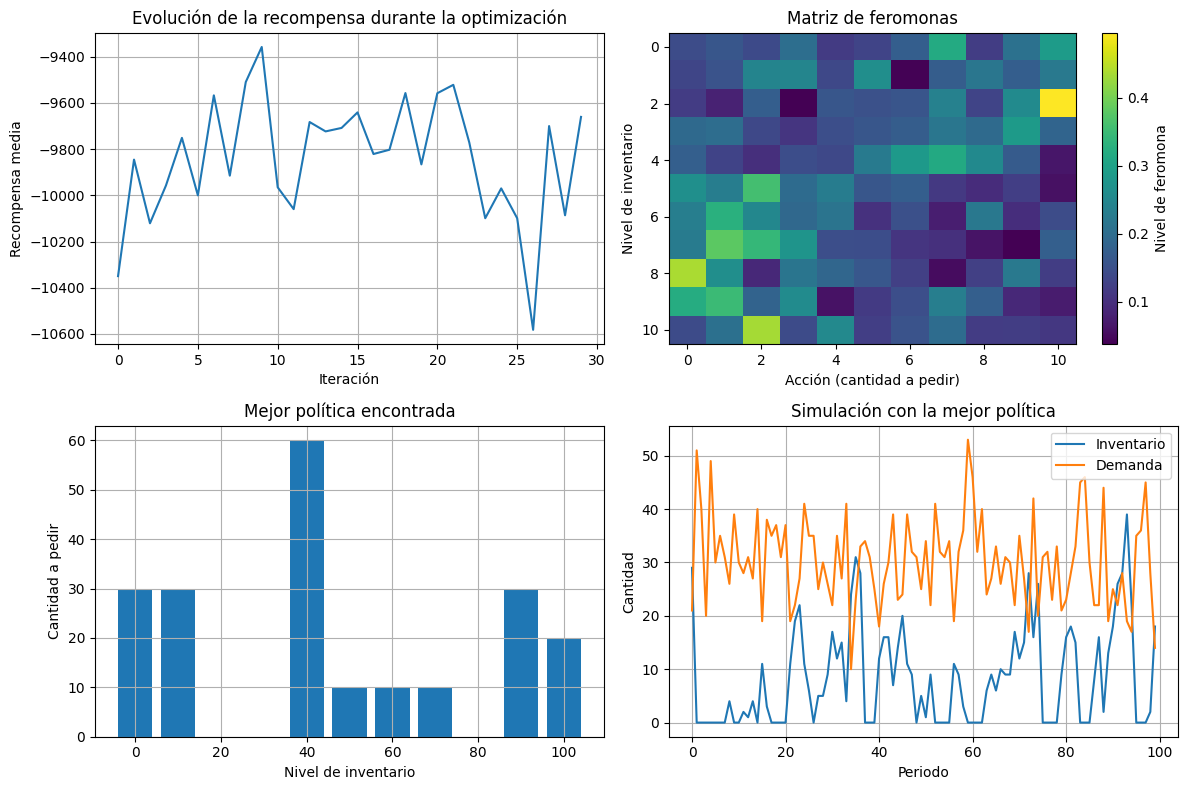

In [23]:
# Visualizar resultados
aco.visualizar_resultados()

In [24]:
# Comparar con una política simple (pedir siempre hasta el 50% de capacidad)
def politica_simple(estado):
    inventario = estado[0]
    objetivo = env.capacidad_max * 0.5
    if inventario < objetivo:
        return int((objetivo - inventario) / (env.capacidad_max / 10))
    return 0

# Evaluar política simple
estado, _ = env.reset()
recompensa_total = 0
for _ in range(100):
    accion = politica_simple(estado)
    estado, recompensa, _, _, _ = env.step(accion)
    recompensa_total += recompensa

print(f"Recompensa con política simple: {recompensa_total:.2f}")
print(f"Recompensa con ACO: {mejor_recompensa:.2f}")
print(f"Mejora: {(mejor_recompensa - recompensa_total) / abs(recompensa_total) * 100:.2f}%")

Recompensa con política simple: -8014.00
Recompensa con ACO: -6726.60
Mejora: 16.06%


La recompensa media de las hormigas oscila de una iteración a otra sin una tendencia clara, mientras que la mejor recompensa mejora pocas veces. En la mayoría de los niveles de inventario, la matriz de feromonas no muestra una acción dominante, lo que indica que en 30 iteraciones la colonia todavía no ha convergido. La mejor política tampoco tiene la forma escalonada de una regla de punto de pedido, pues hay niveles bajos de inventario en los que no pide nada; en la simulación, el inventario pasa muchos periodos en cero o cerca de cero.

Al leer la comparación final hay que tener en cuenta de dónde sale cada cifra. La de la colonia es el mejor promedio de cinco escenarios entre todas las políticas evaluadas durante la búsqueda; la de la regla simple sale de una sola simulación de 100 periodos.